(overview_plots)=
# Overview

ArviZ-plotnine is plotnine version of ArviZ-plots. It comes with "batteries-included" plots, which means it includes a set of predefined plotting functions that cover a wide range of [common use cases](https://arviz-devs.github.io/bayesian-workflow/) in Bayesian data analysis, like MCMC diagnostics, predictive checks, model comparison, and more. These functions are designed to be easy to use, with sensible defaults that allow users to quickly generate high-quality plots without needing to customize every aspect of the visualization. You can take a look at the {ref}`gallery <example_gallery>` to see some examples of the available plots. And you can refer to the {ref}`API reference <plots_api>` for a more detailed description of the available plotting functions.

## Getting Started with ArviZ-plotnine

To start, we’ll import ArviZ. We'll also apply a default style for the plots, this is optional, but it will make the plots look nicer and include nice features like colorblind-friendly palettes.

In [1]:
import arviz_base as azb
import arviz_plotnine as azp9
#azp.style.use("arviz-variat")

To make the example easier to follow we are going to skip the modeling step, and assume we have already built and solve a Bayesian model. ArviZ provides several pre-saved models, so we can use one of those to demonstrate the plotting functionality. In this case we will use the `centered_eight` model, which is a classic, but even if you are not familiar with it, you can still follow along and see how the plotting functions work.

In [2]:
idata = azb.load_arviz_data("centered_eight")

A common task in Bayesian data analysis is to compute the posterior and then inspect it visually. For instance, we can use the `plot_dist` function to visualize the posterior distribution of a model. By default this function produces a plot that shows the distribution of the posterior samples for each parameter in the model.

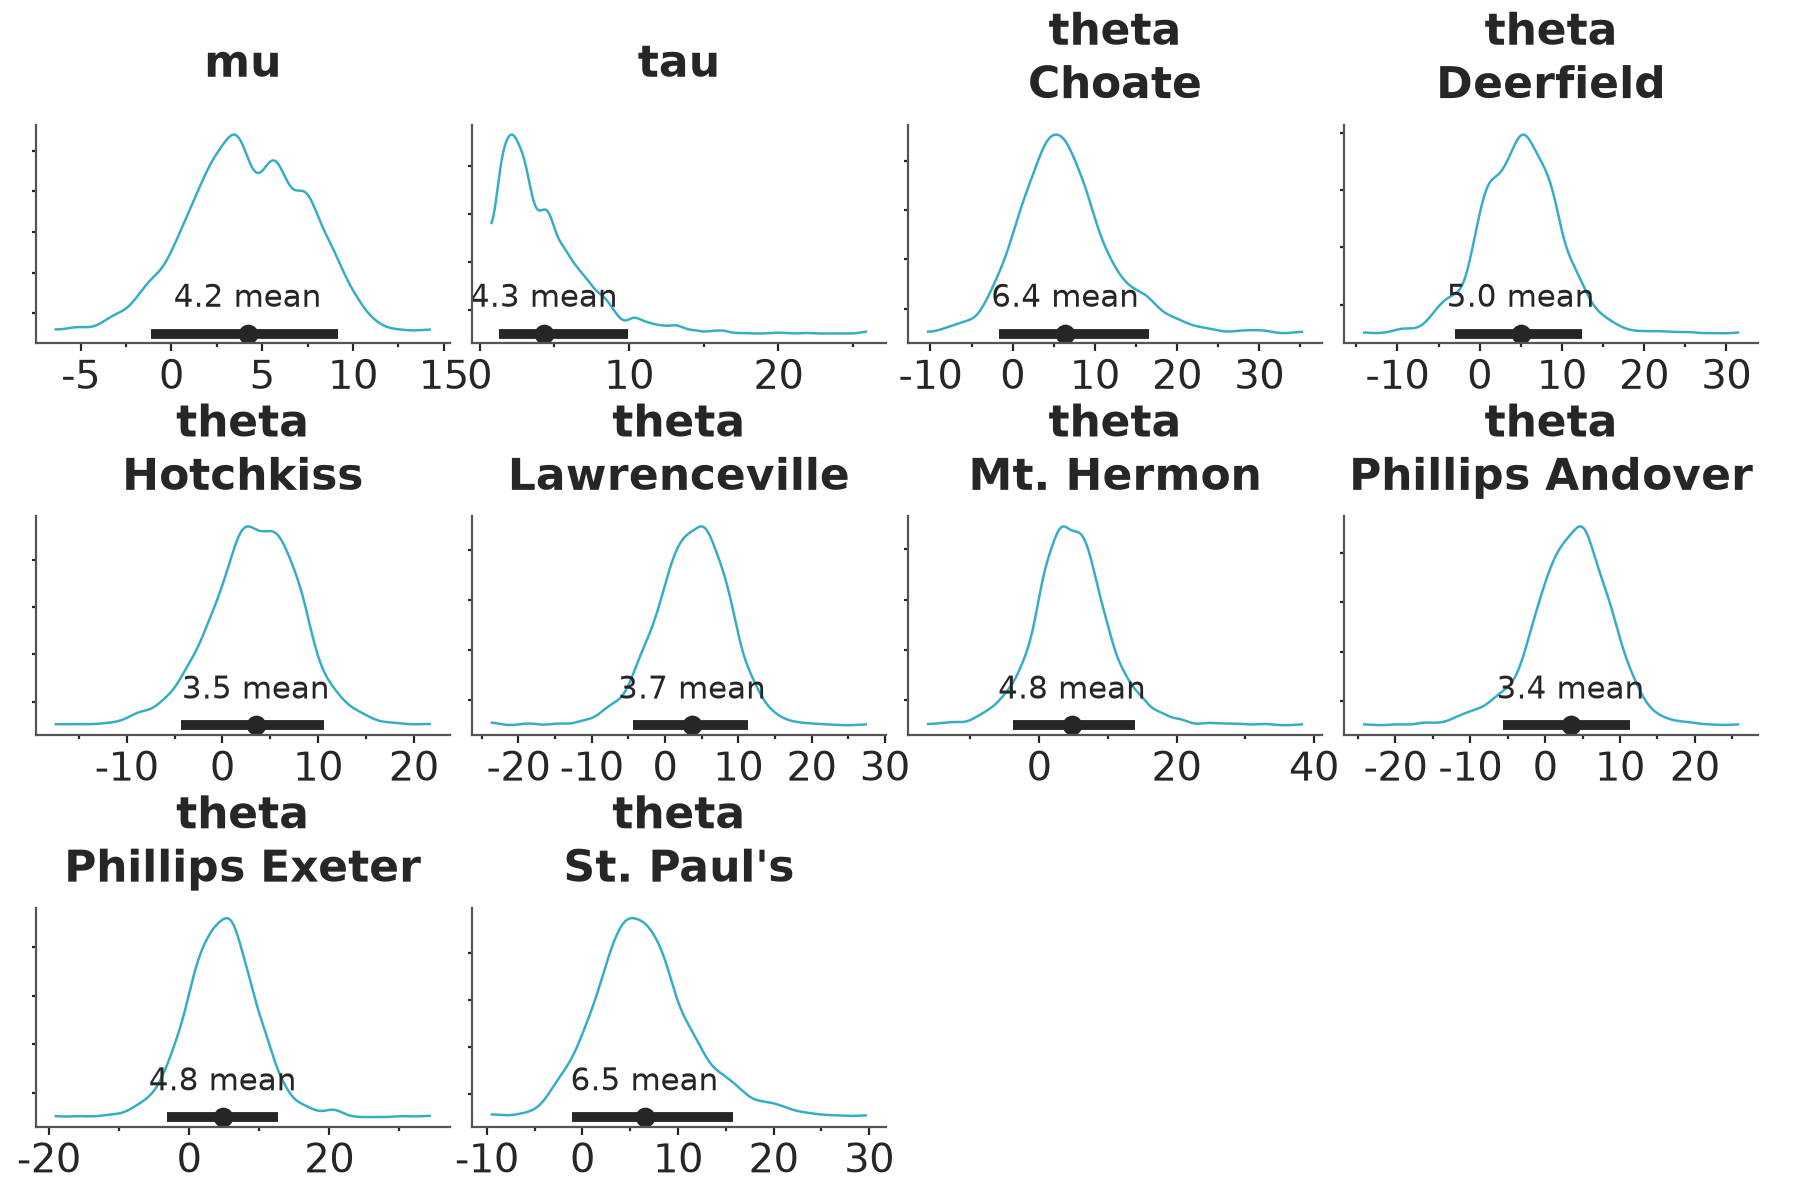

In [3]:
azp9.plot_dist(idata)

As we can see, each marginal of the posterior distribution is represented using a [kernel density estimate (KDE)](https://arviz-devs.github.io/EABM/Chapters/Distributions.html#kde). In this example, there are 3 variables (or parameters), `mu`, `tau` and `theta`, the first two are unidimesional, while `theta` is a vector of length 8. Thus, in total we got 10 plots. In addition to the KDE, the plot includes a point interval showing the mean and the 89% equal-tailed credible interval.

If we want to focus on a specific variable or a subset of variables, we can use the `var_names` argument to specify which ones to display. We simply pass the names of the variables we'd like to plot.

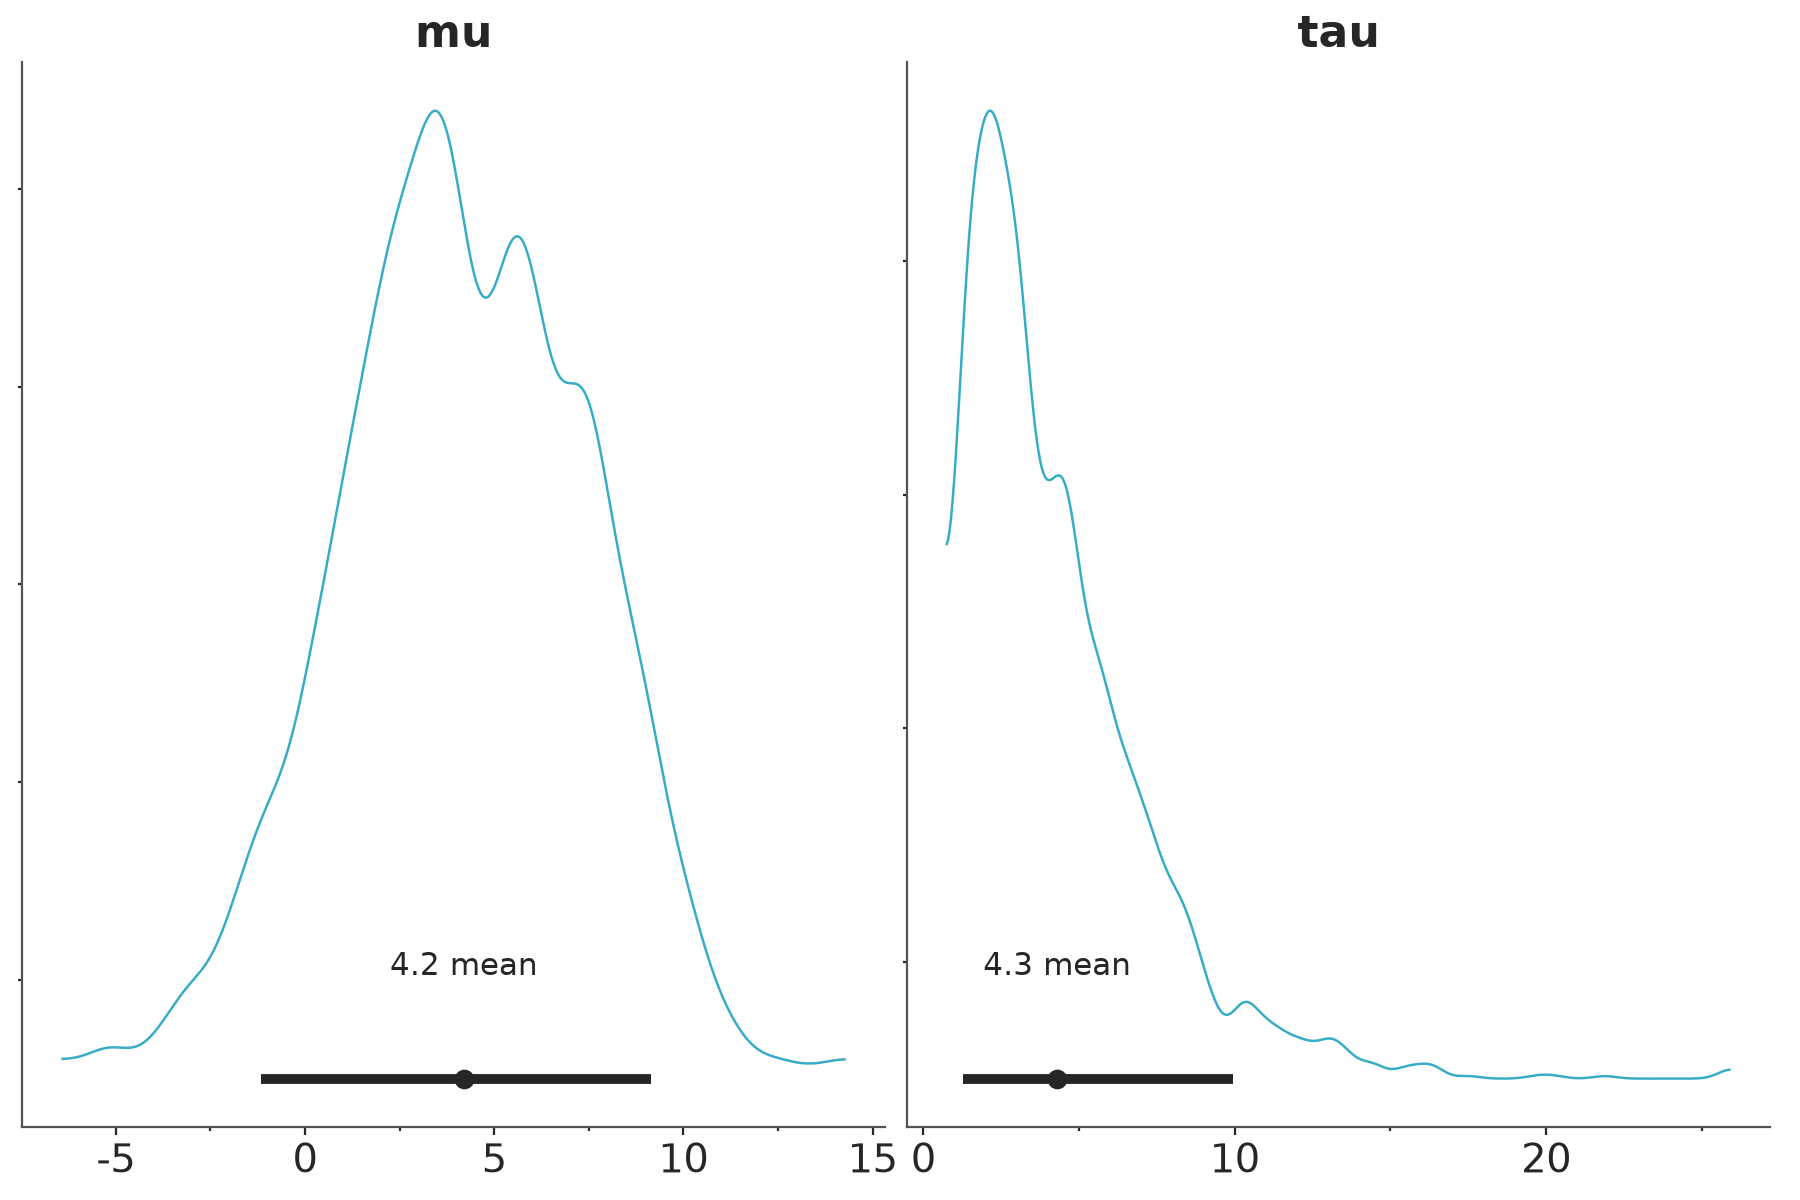

In [4]:
azp9.plot_dist(idata, var_names=["mu", "tau"])

or negate the ones we don't want to plot.


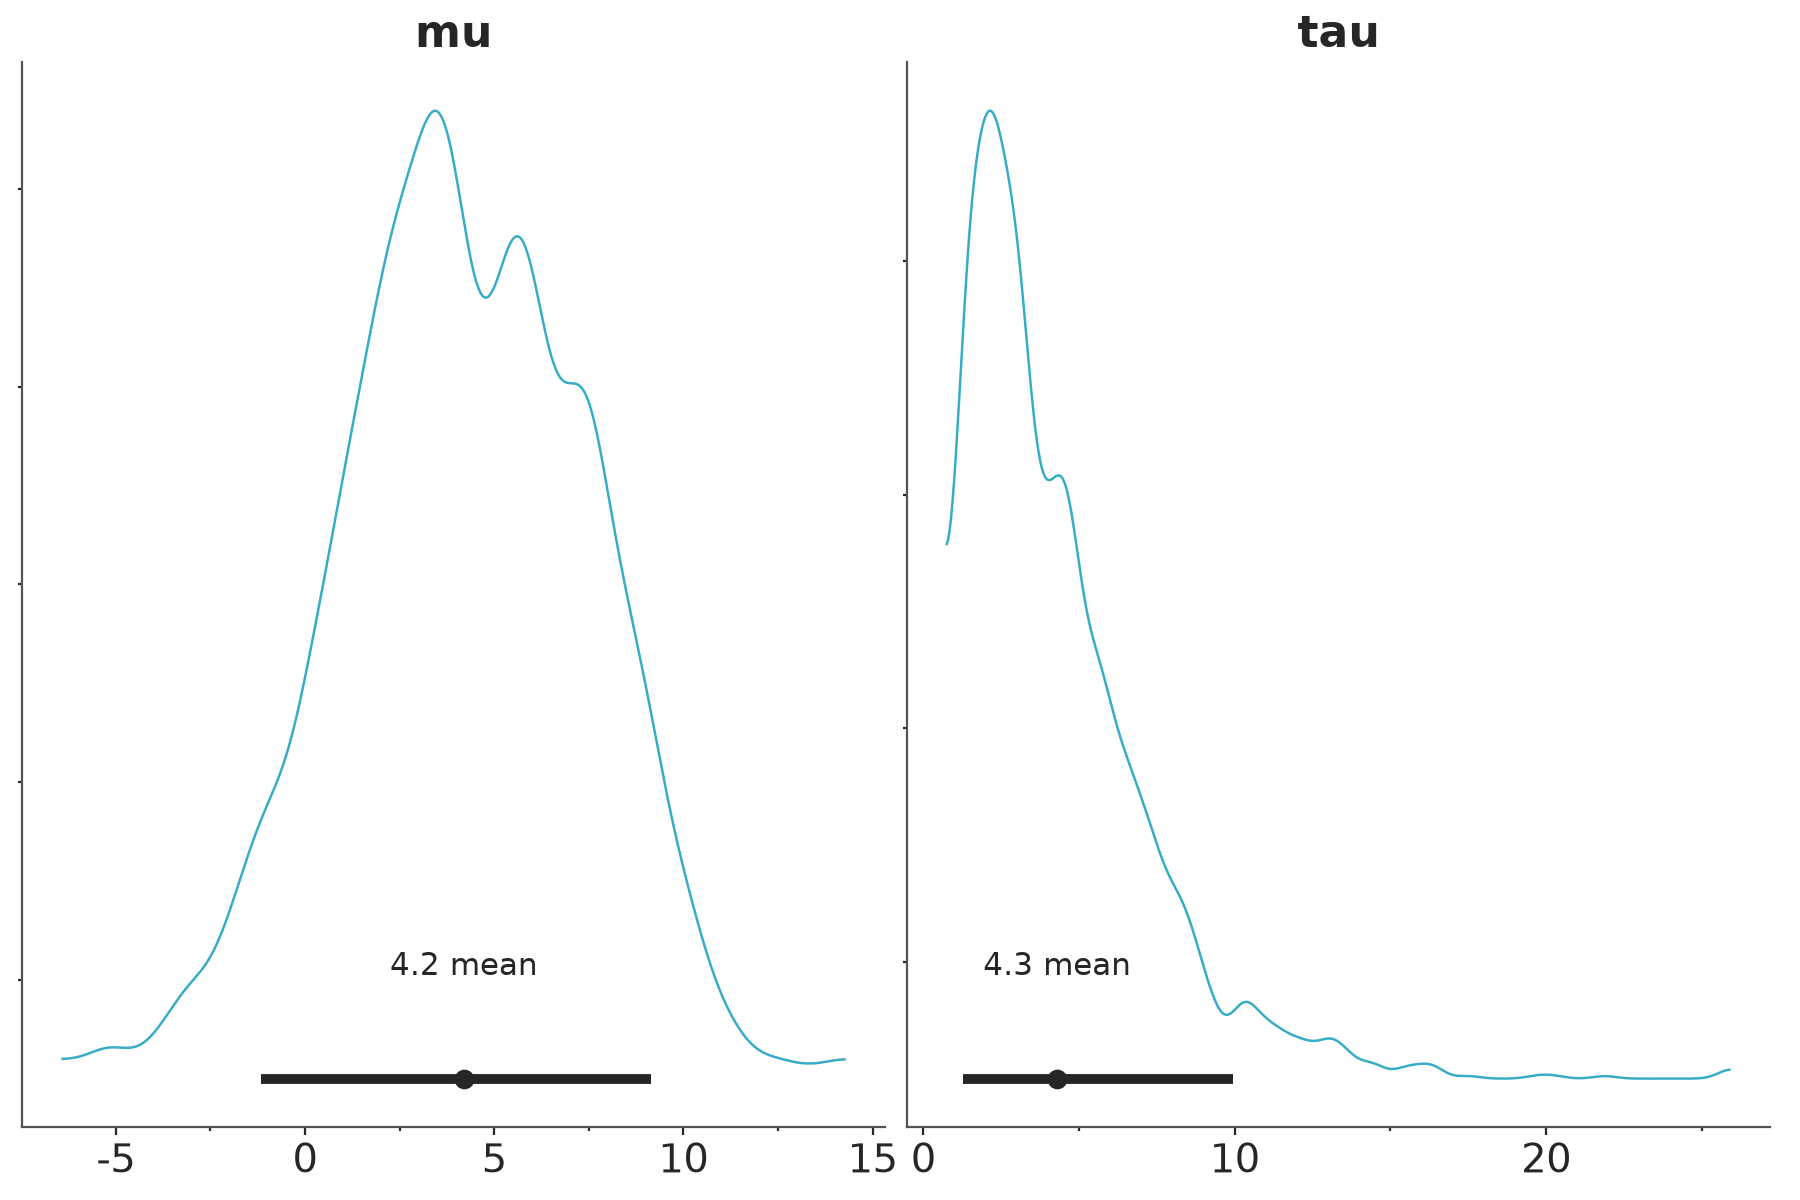

In [5]:
azp9.plot_dist(idata, var_names=["~theta"])

## Exploring groups, dimensions and coordinates

By default, each "batteries-included" plot will use one or more of the available groups. For instance the `plot_dist` function will use the `posterior` group, while the `plot_prior_posterior` function will use both the `prior` and `posterior` groups. These two plots combine the `chain` and `draw` dimensions to produce the final plot. That's why we get a single plot for each variable (each one consisting of 2000 samples, 4 chains x 500 draws). But notice that the dimension `school` is not "reduced", instead it is used to facet the data, i.e. we get a separate plot for each school.

All these defaults can be changed. Usually ArviZ plotting function will have a `group` argument. How flexible this argument is depends on the function, one on extreme `plot_prior_posterior` ignores this argument and always uses the `prior` and `posterior` groups, while on the other extreme `plot_dist` is very flexible and allows us to specify many groups we may want to plot.

Let's set group to `posterior_predictive`. Can you anticipate what we will get?

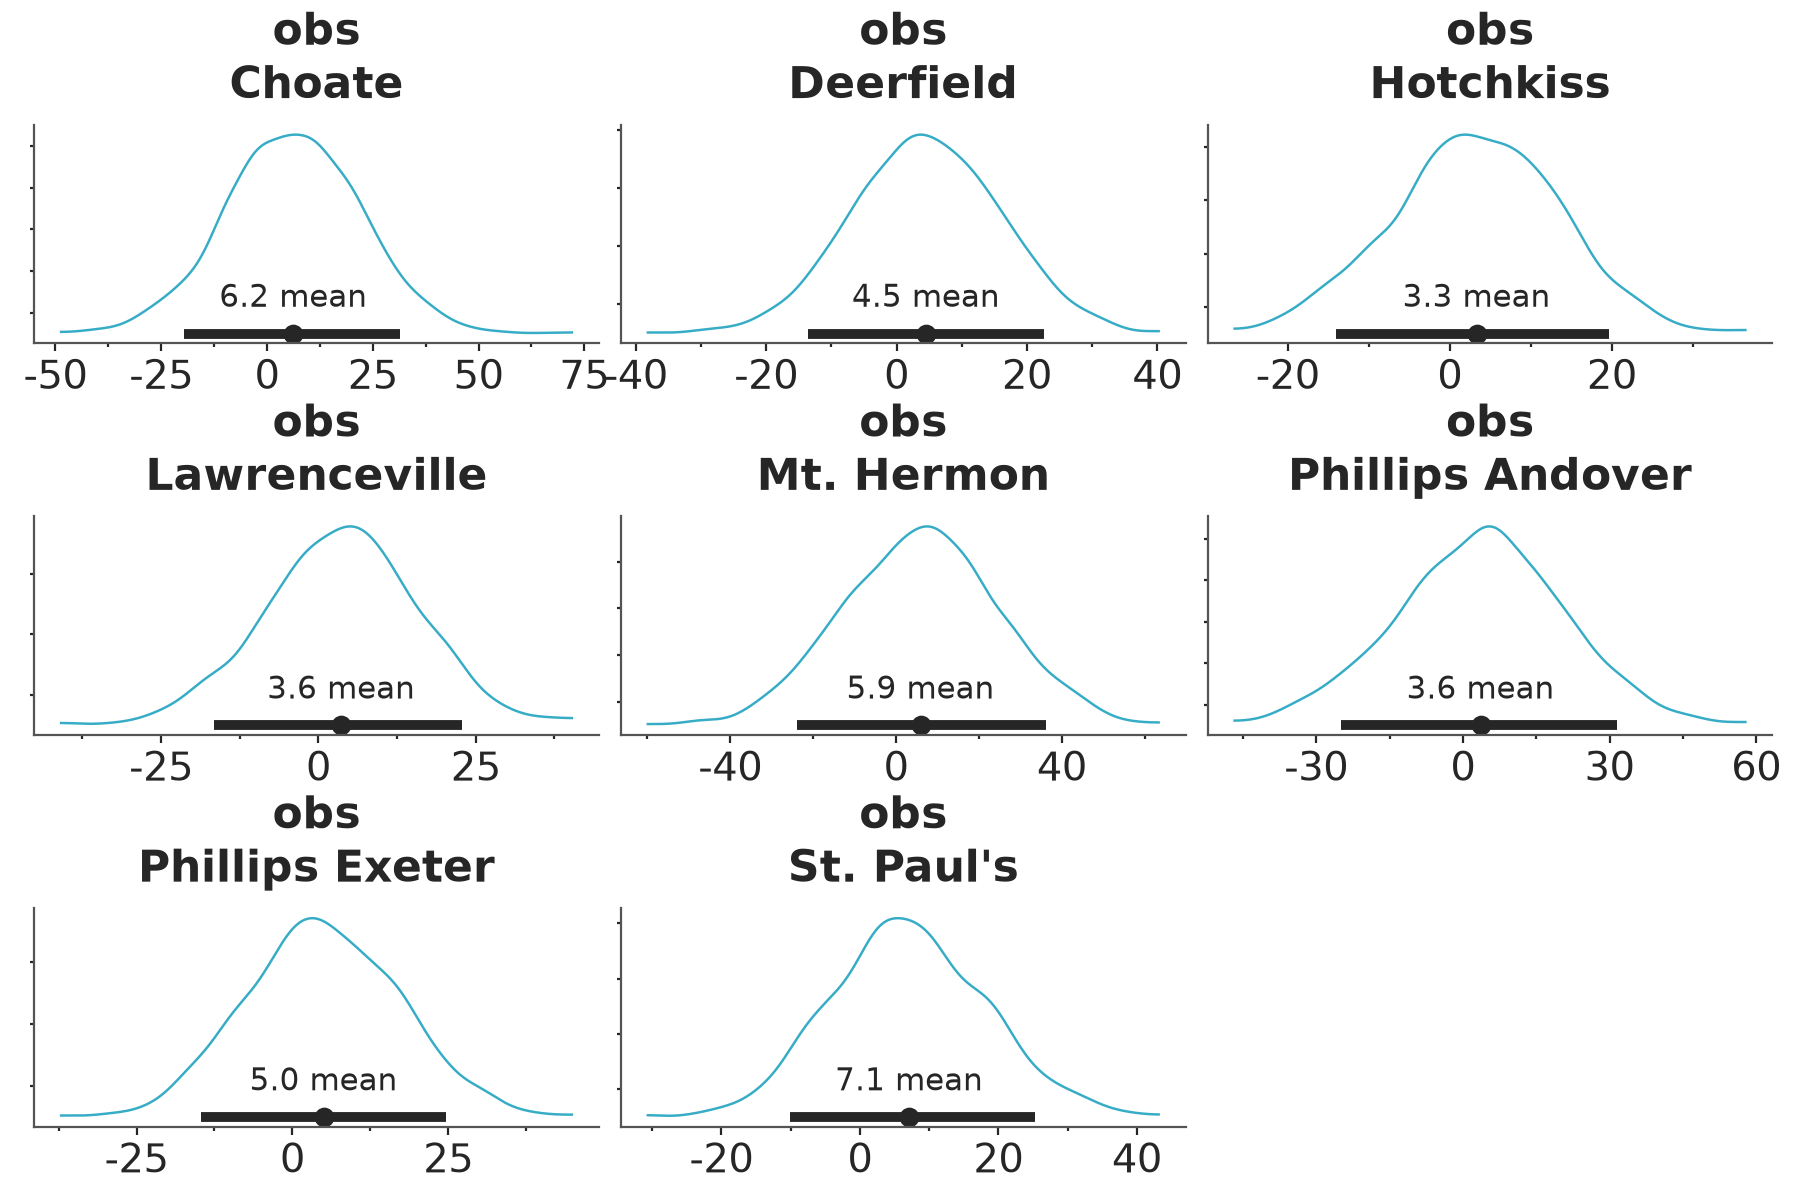

In [6]:
azp9.plot_dist(idata, group="posterior_predictive")

We get predictions of the model at each observation. In this example, we have 8 observations, so we get 8 plots.

ArviZ does not come with guarantees that any possible combination of arguments that you may want to try will work. ArviZ aims at having sensible defaults, but then you are free to explore the data as you wish and be responsible for the results.


For instance

```python
az.plot_dist(idata, group="sample_stats")
```

will not work, because the `sample_stats` group does not contain any samples to plot. However,

```python
azp.plot_dist(idata, group="log_likelihood");
```

will work, and it will plot the log-likelihood of the model for each observation. This is not a common use case, but it may be useful in some situations.


Results may vary for different models, for instance.

```python
idata_radon = azp.load_arviz_data("radon")
azp.plot_dist(idata_radon, group="posterior_predictive");
```

will run, but it may crash your session, because for the `radon` model the `posterior_predictive` group contains 919 observations. So the above code will try to plot 919 KDEs!, which may be too much for your system to handle.

----

We want to note that you can use `.plot_dist(dt, group="posterior_predictive")` to do posterior predictive checks, actually `plot_ppc_dist` is using it. However, it will require more effort on your part, as you will need to adjust several other arguments and take additional steps to obtain a meaningful result. That's why ArviZ offers many batteries-included plots.

### Sample_dims

Now, we are going to discuss the `sample_dims` argument. This argument is used to specify which dimensions of the data should be reduced when plotting. An example will help us understand this better. Let's say we want to use the `plot_dist` function to visualize the distribution of the data. If we do:

```python
azp.plot_dist(idata, group="observed_data");
```

We will get an error. By default, `sample_dims` is set to `["chain", "draw"]`, but those dimensions are not present (or meaningful) in the `observed_data` group, instead the observed data has a `school` dimension. We may want to do is to reduce (or marginalize over) this dimension. That is to see the distribution of the data for all schools combined. If that is the case, we can set `sample_dims` to `["school"]`.

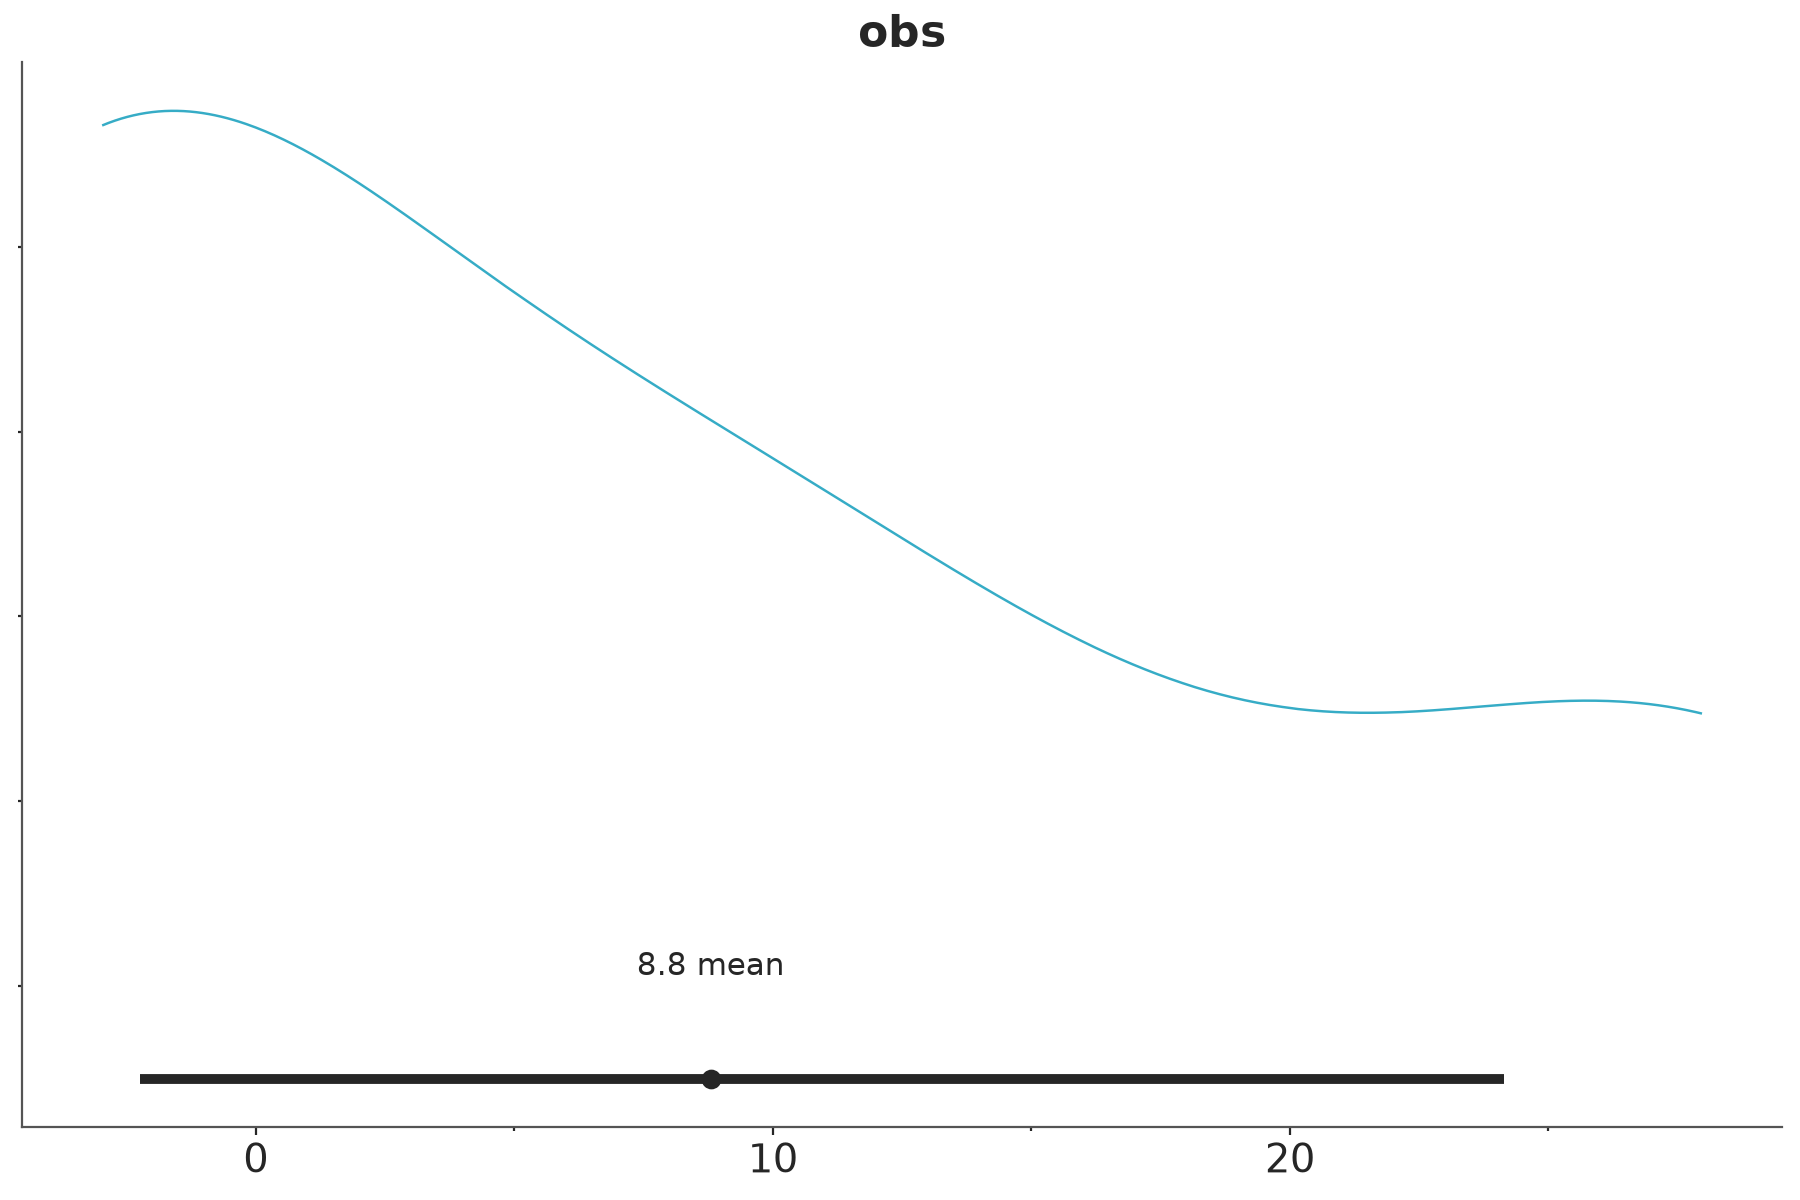

In [7]:
azp9.plot_dist(idata, group="observed_data", sample_dims=["school"])

If we were interested in the posterior distribution for `mu` per `chain`, we could do:

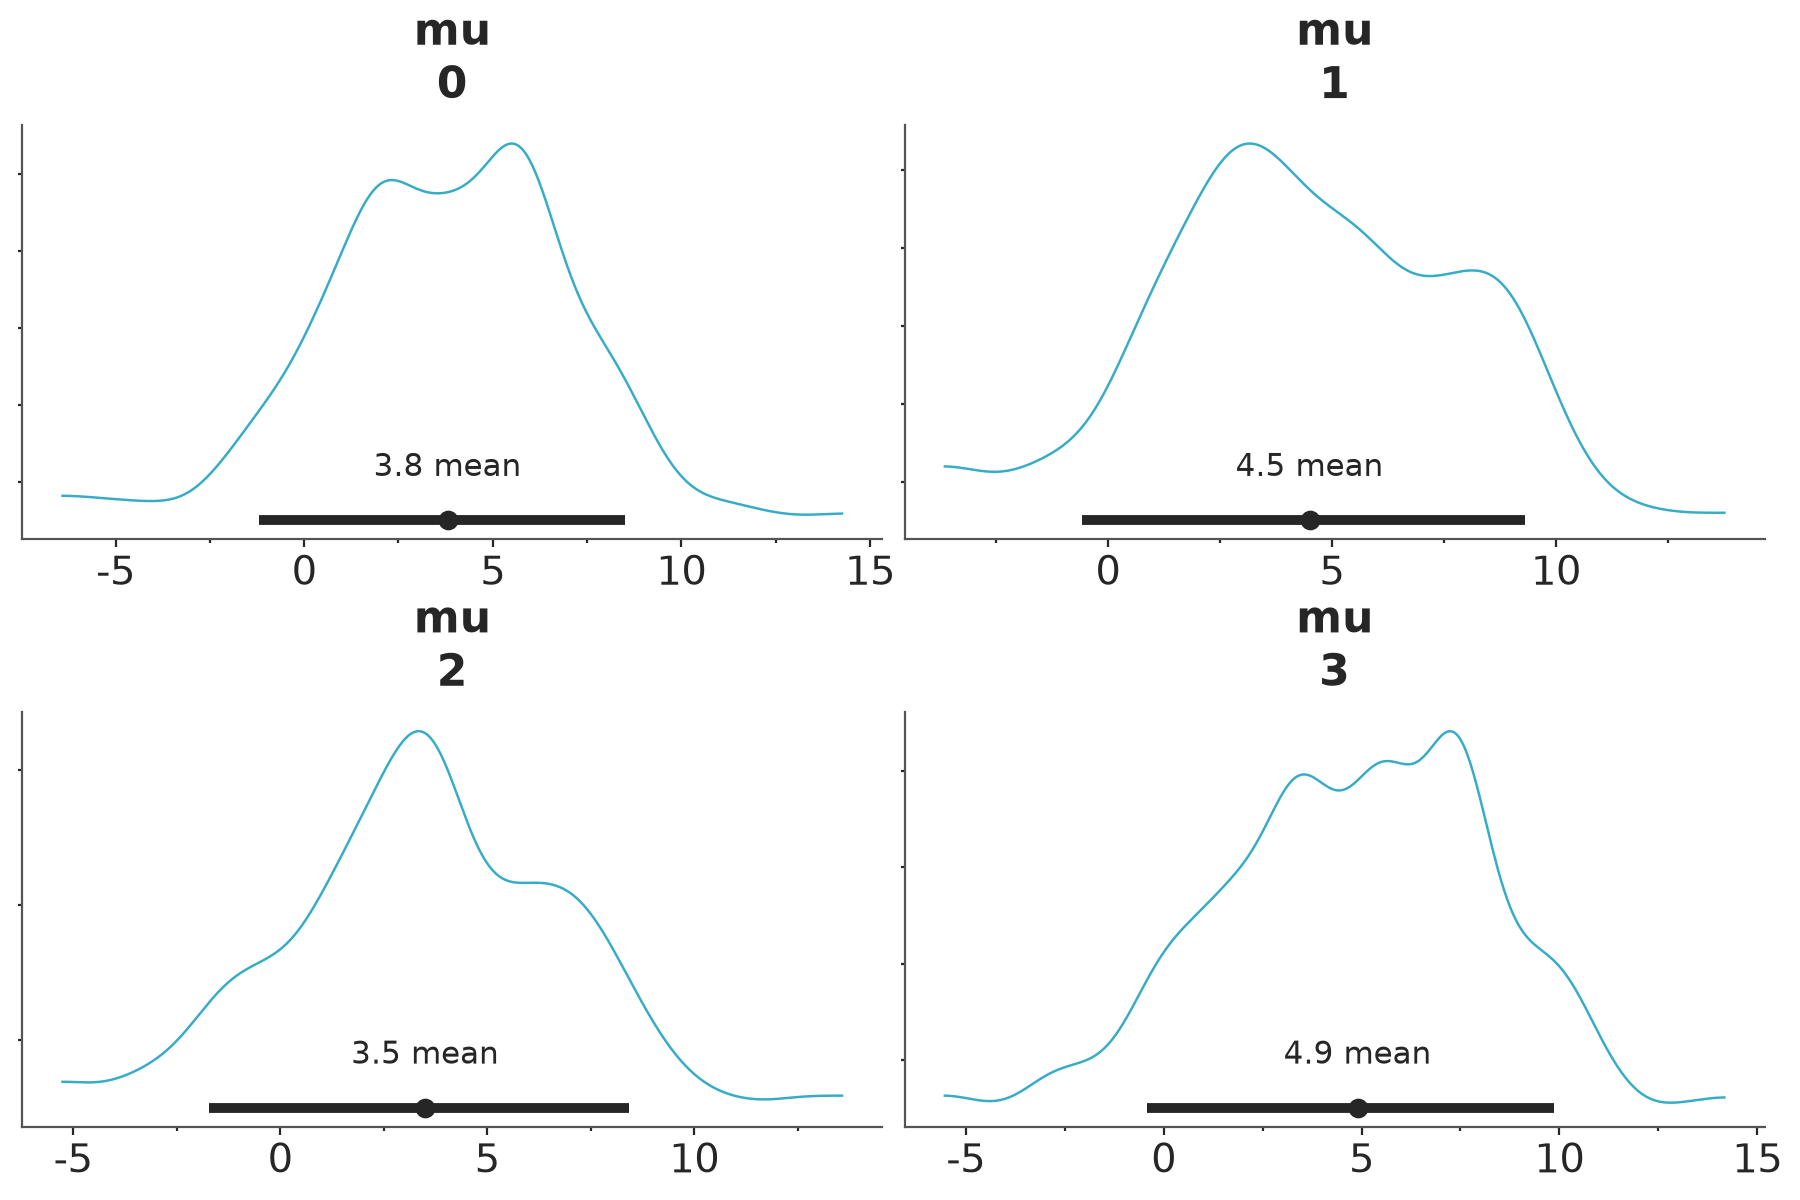

In [8]:
azp9.plot_dist(idata, var_names=["mu"], sample_dims=["draw"])

A KDE that appears overly spiky or irregular may indicate issues with specific chains, such as poor convergence or pathological sampling behaviour. However, diagnosing these issues is beyond the scope of this tutorial, to learn more about MCMC diagnostics, please refer to the [MCMC Diagnostics](https://arviz-devs.github.io/EABM/Chapters/MCMC_diagnostics.html) chapter from the EABM guide.

### Coords

We can use the `coords` argument to specify which **coordinates** we want to use for the plot. This is useful to filter variables across dimensions. For instance, if we want to plot the posterior distribution of only a subset of schools, we can do:

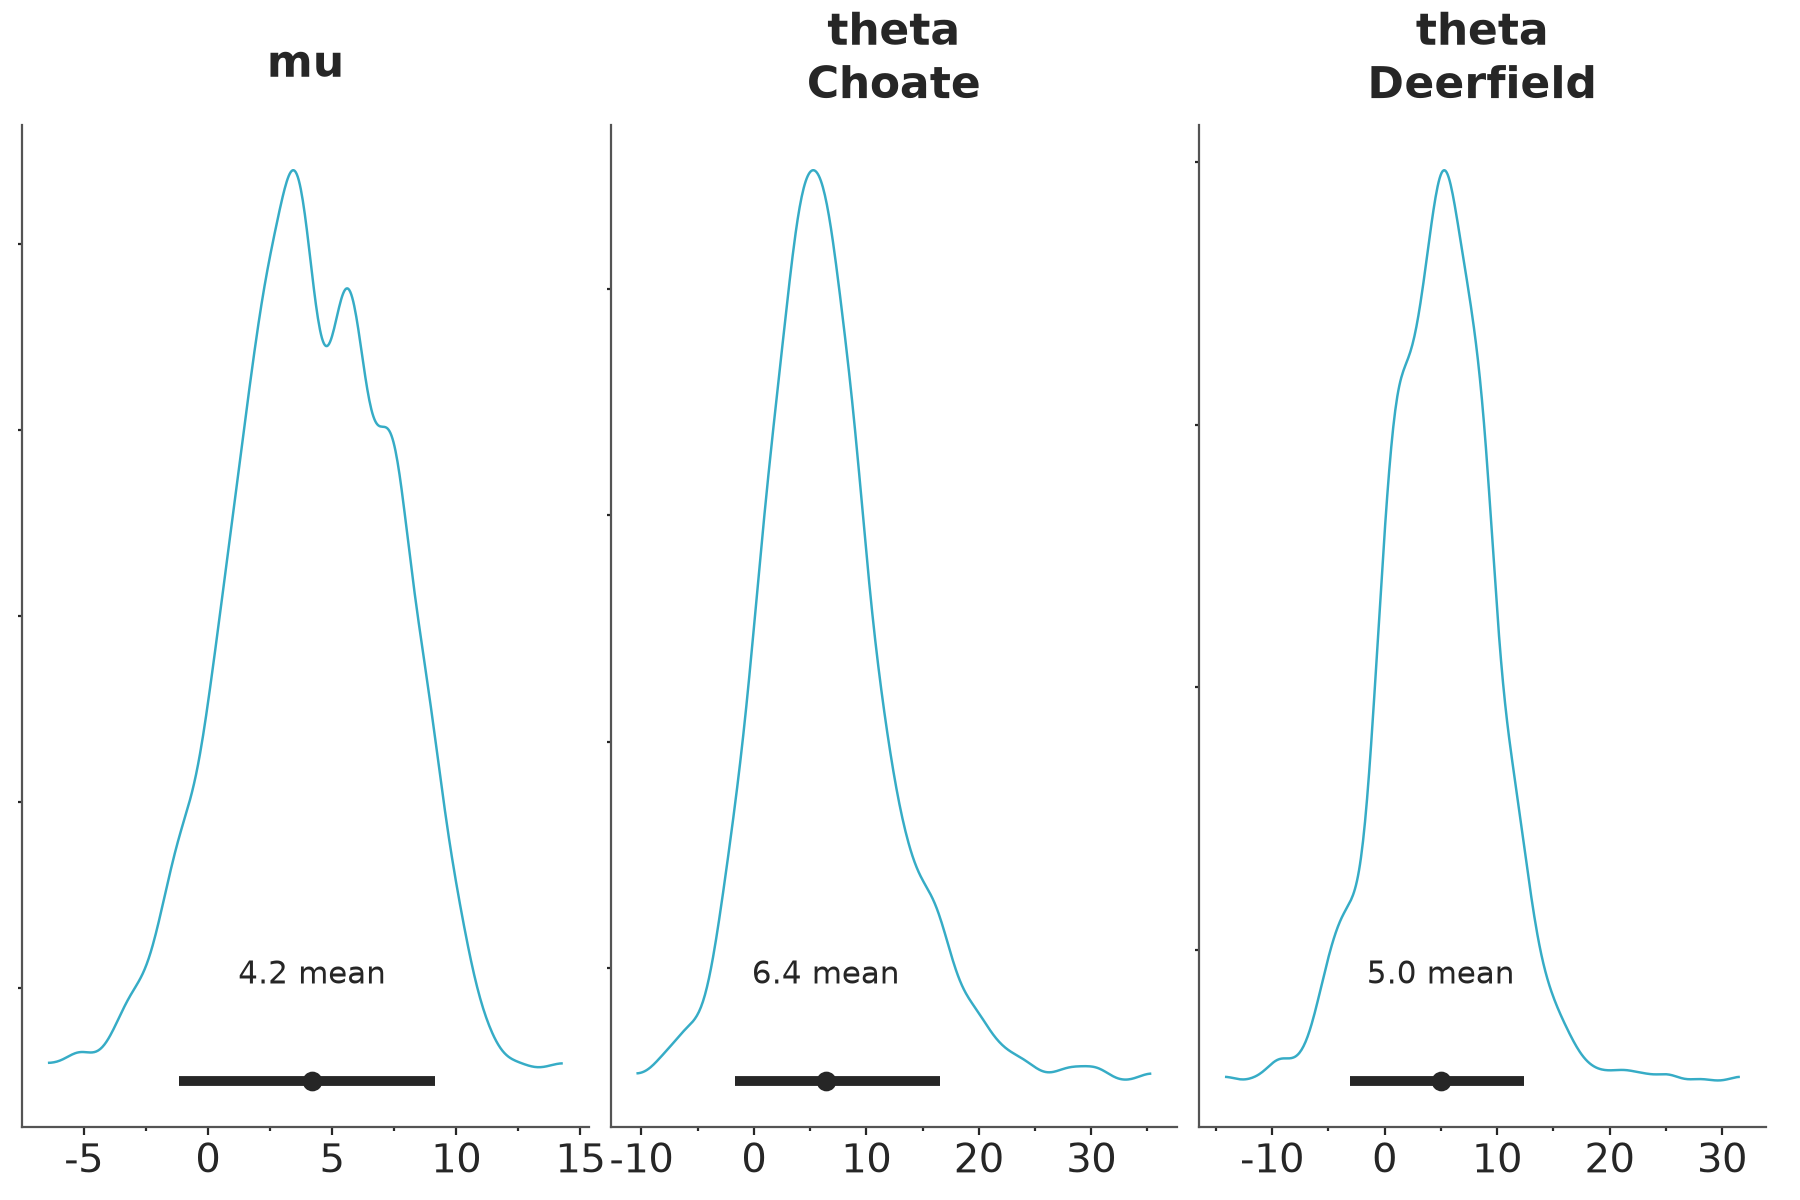

In [9]:
azp9.plot_dist(
    idata,
    var_names=["mu", "theta"],
    coords={"school": ["Choate", "Deerfield"]},
)

Notice that the `coords` argument is used to select specific schools and thus it does not affect variables without the school dimension, like `mu`.

## Global defaults

ArviZ provides a set of global defaults that, once modified, influence the behaviour of multiple functions across the library. ArviZ's plots, like `plot_dist` takes from here the default value for `sample_dims` and other arguments. They are stored in `azb.rcParams`, for further details you can read {ref}`arviz_base:arviz_configuration`. Can you spot, the default values for interval and their probability?

In [10]:
azb.rcParams

RcParams({'data.http_protocol': 'https',
          'data.index_origin': 0,
          'data.sample_dims': ('chain', 'draw'),
          'data.save_warmup': False,
          'plot.backend': 'matplotlib',
          'plot.density_kind': 'auto',
          'plot.max_subplots': 40,
          'stats.bfmi_threshold': 0.3,
          'stats.ci_kind': 'eti',
          'stats.ci_prob': 0.89,
          'stats.envelope_prob': 0.99,
          'stats.ic_compare_method': 'stacking',
          'stats.ic_pointwise': True,
          'stats.ic_scale': 'log',
          'stats.module': 'base',
          'stats.point_estimate': 'mean',
          'stats.round_to': '2g'})

If we don't like the default value of 0.89 for the credible interval, we can change it globally:

```python
azb.rcParams["stats.ci_prob"] = 0.9
```

This will change the default value for the credible interval to 0.9 for all subsequent calls to `plot_dist` and other functions that use this parameter, or we can change it per call:

```python
azp.plot_dist(data, group="posterior", ci_prob=0.9)
```

## More about arguments

Let's summarize what we have learned about the arguments of the plotting functions.

We have seen that ArviZ plotting functions have a set of arguments that allow us to customize the plots. Some arguments are shared across all (or almost all) plotting functions:

* `var_names`: This argument allows us to specify which variables we want to plot. 
* `group`: This argument allows us to specify which group of data we want to use for the plot.
* `sample_dims`: This argument allows us to specify which dimensions to reduce. 

We have also seen that some arguments are specific to each plotting function (or related functions). For instance, we have seen that `plot_dist` has a `kind` and a `ci_prob`.

What about other common arguments that one see in other plotting libraries? For instance, `color`, `linestyle`, `figsize`, `bins` (for histograms) or `bandwidth` (for KDEs). If you inspect the docstring for `plot_dist` you will notice that there are no arguments with such names. In the next sections we will see a set of arguments that allow us to customize the plots, and they are shared across all (or almost all) plotting functions. A summary of these arguments is provided below and examples of their usage will be provided in the following sections:

* `visuals`: Each element you see in a plot is a visual, like a line, a point, a bar, a band, etc. Each visual has a set of properties that can be customized, like color or linestyle. The `visuals` argument allows to specify these properties and also to specify which visuals we want to include in the plot.

* `stats`: Controls the statistical computations used to construct the visual elements. For example, a KDE needs a `bandwith` that controls the smoothness of the curve and a histogram needs a `bins` argument that controls the number of bins. Usually the defaults are good enough, but we can use this argument to change them.

* `aes_by_visuals`: Controls which aesthetic mappings are applied to which visual elements. For example, we can map `school` to `color` for the KDE while also applying the same mapping to the point estimate.

* `pc_kwargs`: ArviZ plots are built on top of a `PlotCollection` object. This argument controls the arguments that are passed to it. And we can use it to control aspect such as figure size, faceting, etc.


### visuals

In ArviZ, we use the {term}`visual` to reference to the graphical elements we see in a plot, like a title, a KDE, a credible_interval, etc. 

The `visuals` argument expects a dictionary where the keys are the names of the graphical elements and the values are dictionaries that specify the properties of those elements. Alternatively, the values can be `True` or `False`, in case we want to add/remove one visual. The keys depend on the plotting function, for example `plot_dist` has a visual called `dist`, which is a representation of a distribution. Exactly which representation, KDE, histogram, etc depends on the value of the `kind` argument.

For example to change the color of the KDE we can do:

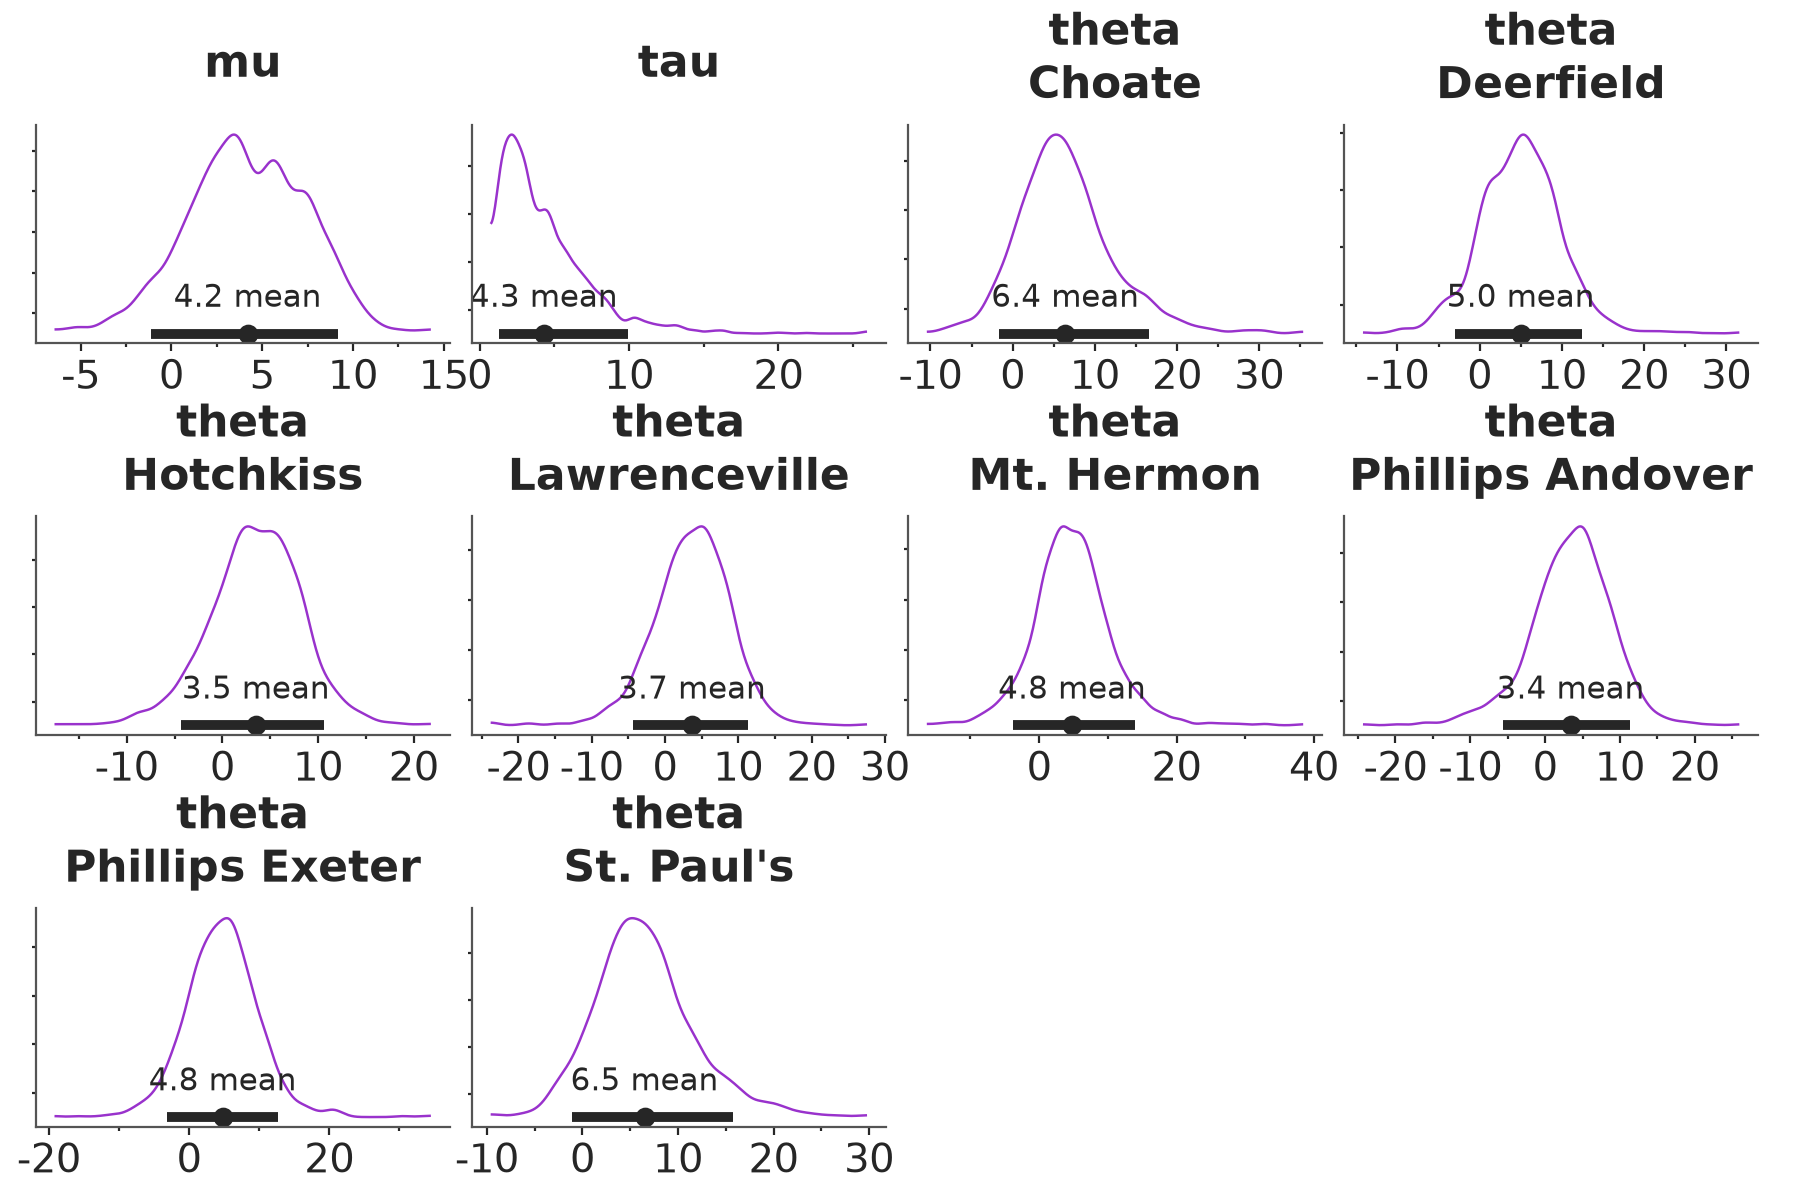

In [13]:
azp9.plot_dist(idata, visuals={"dist": {"color": "darkorchid"}})

To find the valid keys for `visuals`, you can check the docstring of each function. For `plot_dist` we have:

* dist
* face
* credible_interval
* point_estimate
* point_estimate_text
* rope
* rope_text
* rug
* remove_axis
* title

Some of these visuals are present in the plot by default, while others are not. For instance, `dist`, `credible_interval`, and `point_estimate` are present by default, while `face`, `rope`, and `rug` are not. `remove_axis` allows us to remove the `y-axis` from the plot.

Let's play a bit with the `visuals` argument, so we get more familiar with it. Let's remove the line representing the distribution


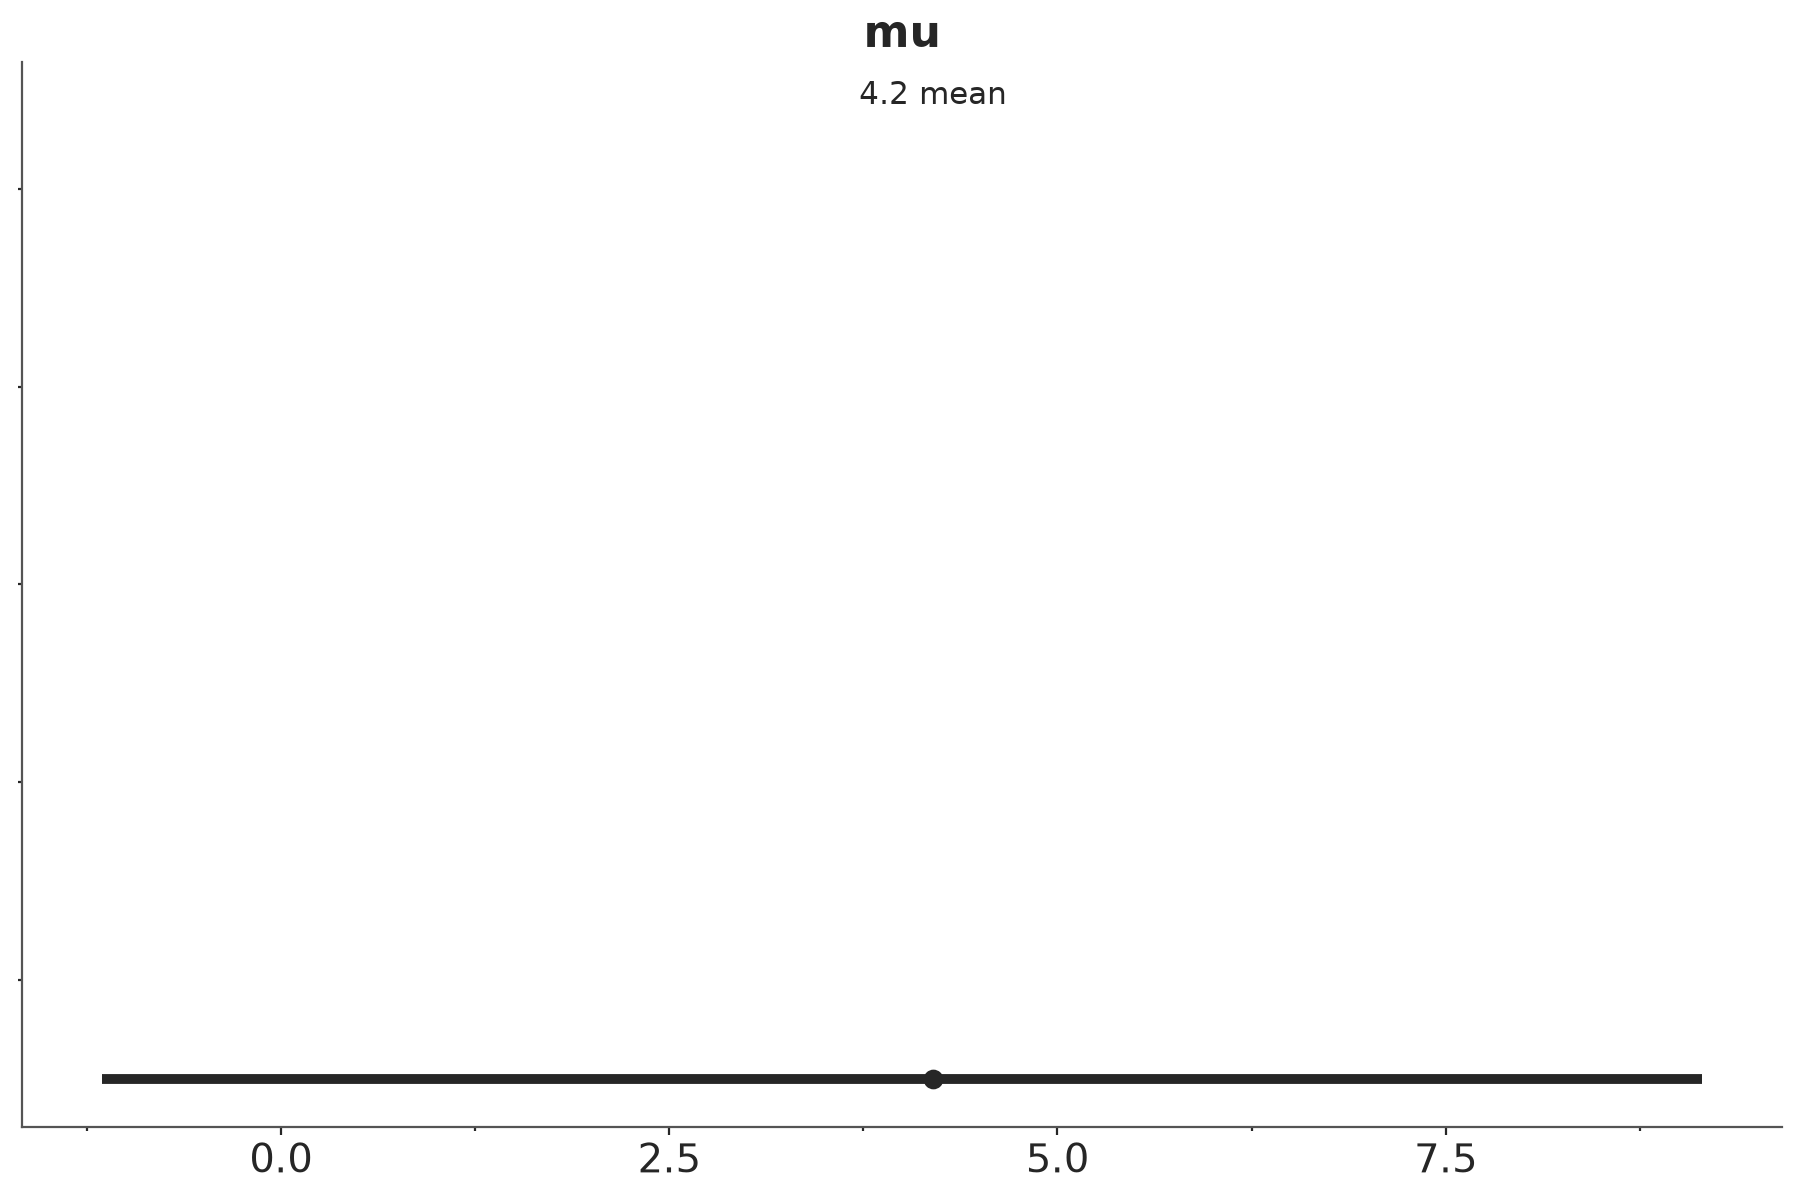

In [15]:
azp9.plot_dist(
    idata,
    var_names=["mu"],
    visuals={
        "dist": False,
    },
)

And now let's add a filled area under the curve of the distribution (a "face"), and customize its color and transparency using the `color` and `alpha` properties, respectively.

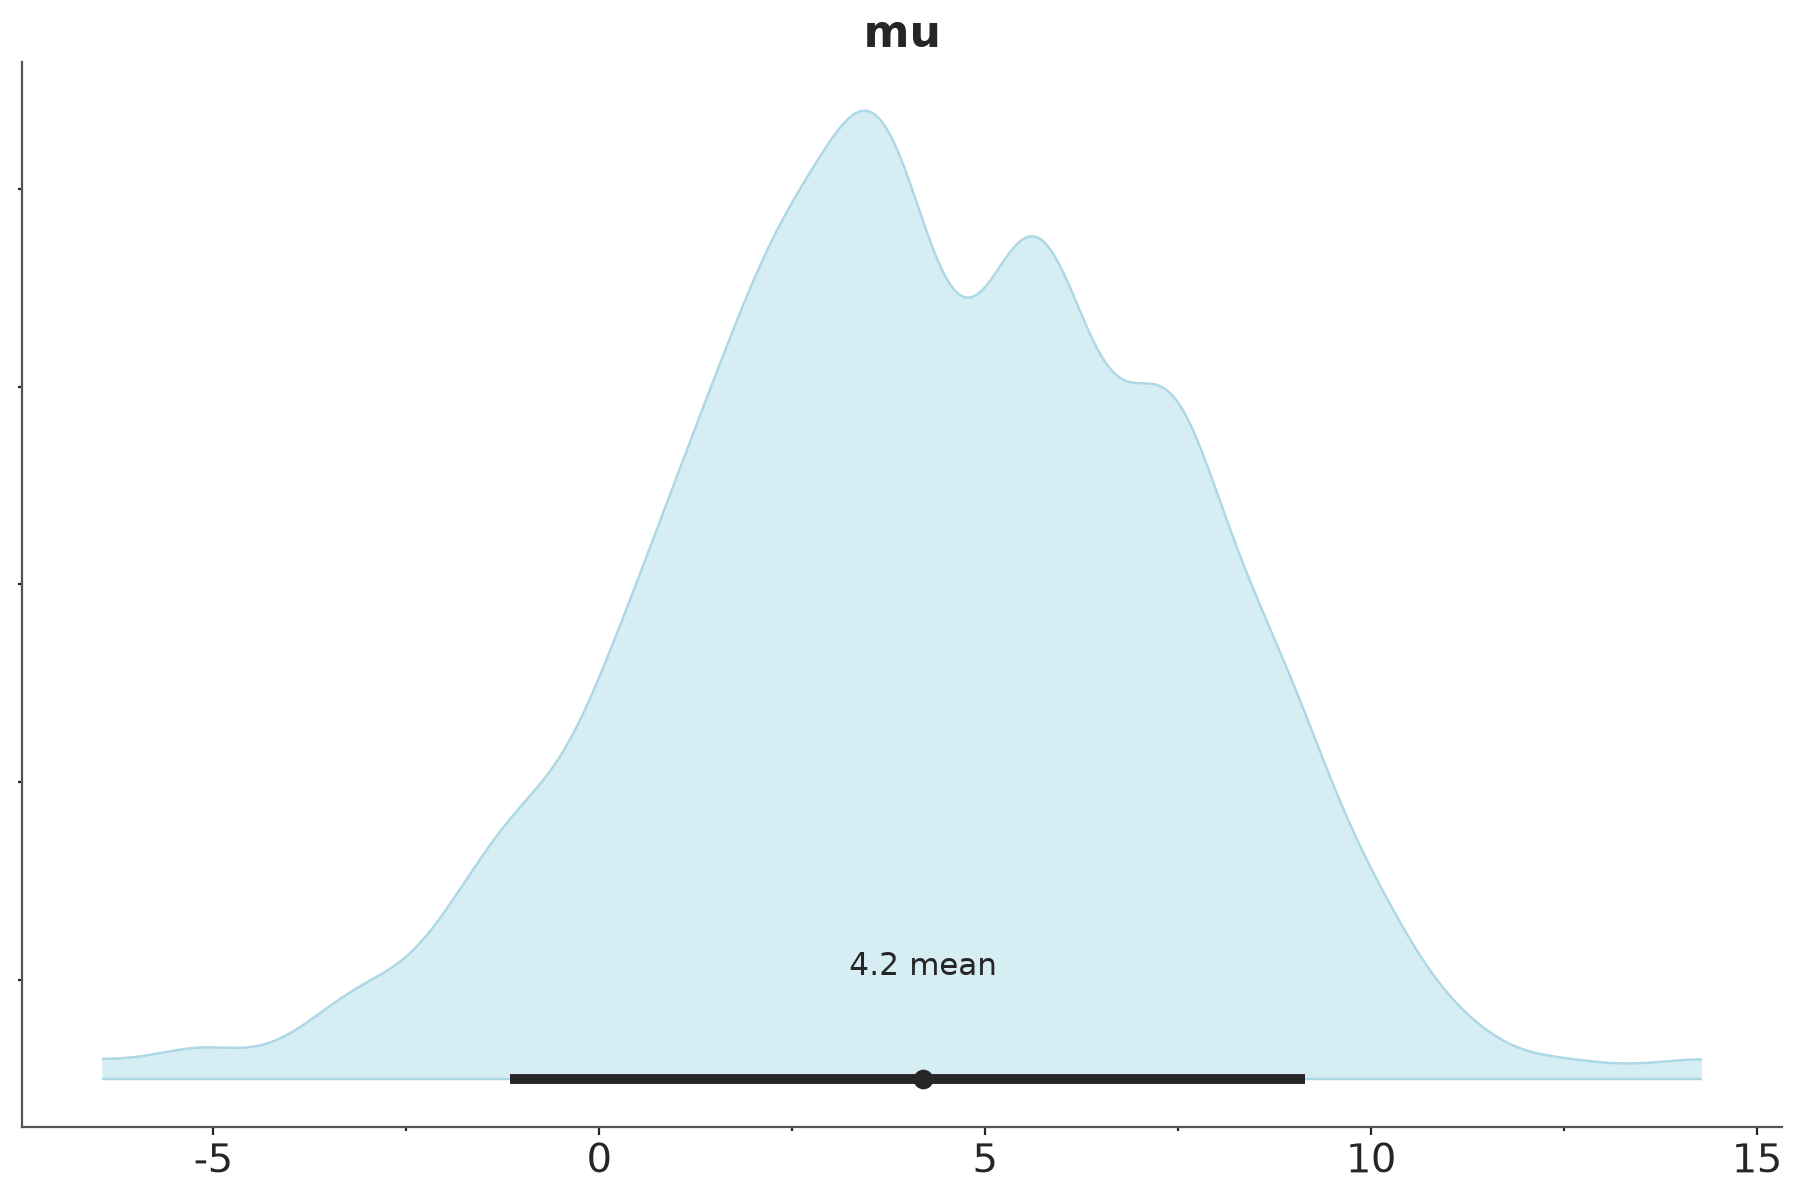

In [18]:
azp9.plot_dist(
    idata,
    var_names=["mu"],
    visuals={
        "dist": False,  # remove the line representing the distribution
        "face": {"alpha": 0.2, "color": "lightblue"}, # add a "face" and customize it
    },
)

Or change figure properties like `figsize`, or `sharex`, etc.

Or we can add an aesthetic mapping, that is, we can map a property of the data to a visual property of the plot. For instance, we can map the `school` dimension to the color of the distribution:

In [ ]:
azp9.plot_dist(
    idata,
    aes={"color": ["school"]},
)

NameError: name 'azp' is not defined

The variables `mu` and `tau` don't have a `school` dimension, so is not possible for them to satisfy the mapping, and thus ArviZ assigns them the same color. We say this color is "neutral" because is not encoding any specific information.

### aes_by_visuals


In the previous example we told ArviZ to map the `color` argument to the `school` dimension. But the only affected visual was `dist`. The reason is that by default the `color` aesthetic is only mapped to `dist`. To change this default we need to use the `aes_by_visuals` argument.

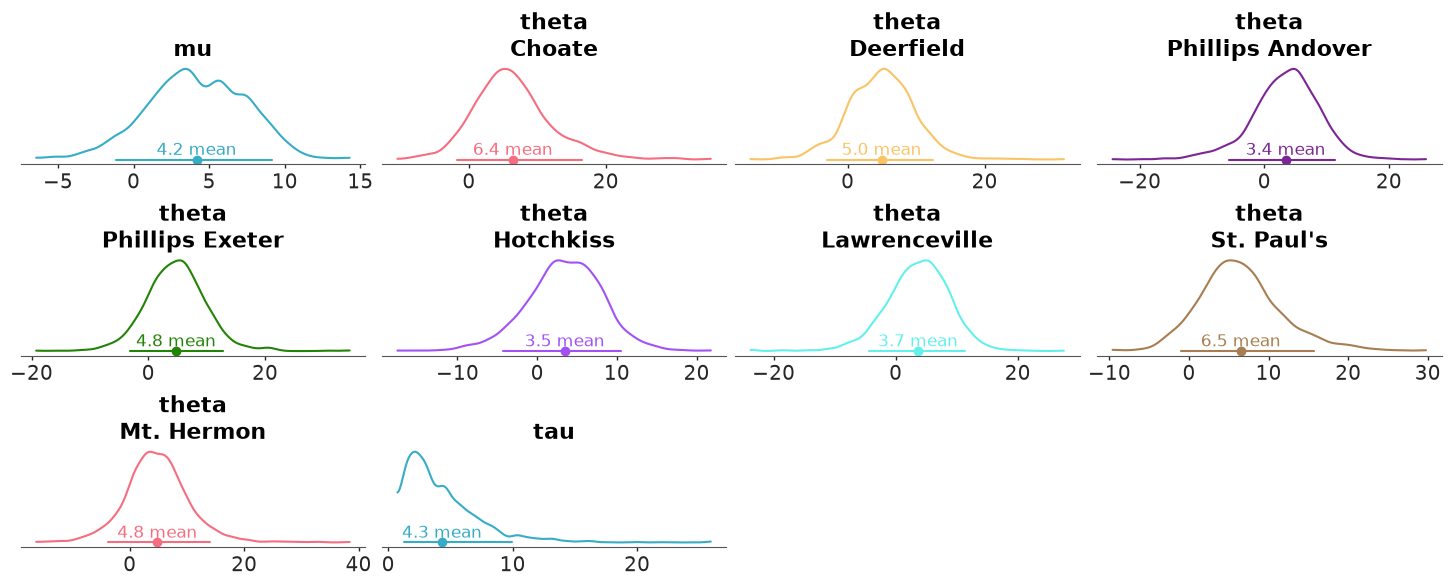

In [ ]:
azp.plot_dist(
    idata,
    aes={"color": ["school"]},
    aes_by_visuals={
        #"kde": ["color"], # this is the default, so it can be omitted
        "point_estimate": ["color"],
        "credible_interval": ["color"],
    },
);


### Recap (using all arguments)

Let's summarize this section with two example that brings together the arguments we have discussed so far. Try commenting out individual arguments and running the example again to see how each one affects the resulting plot.

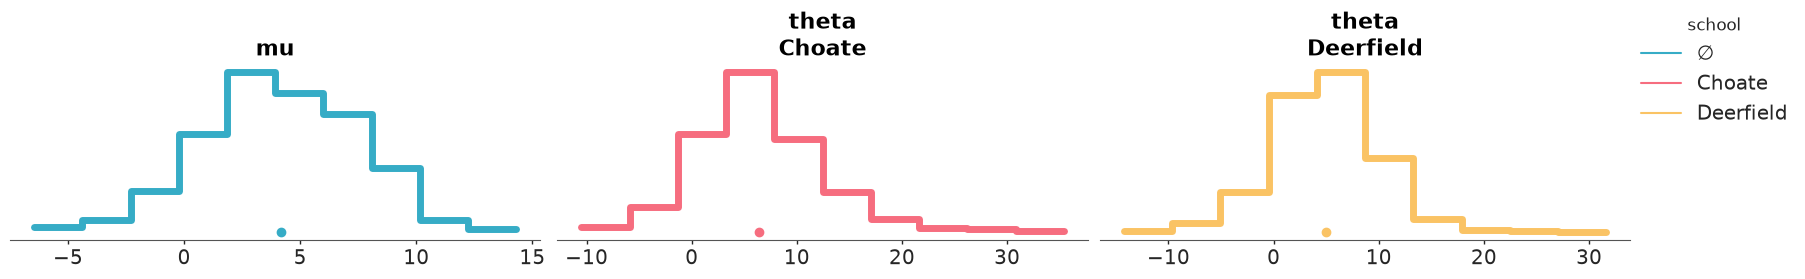

In [ ]:
pc = azp.plot_dist(
    idata,
    var_names=["mu", "theta"],  # select only two variables
    coords={"school": ["Choate", "Deerfield"]},  # select only two schools
    kind="hist",
    aes={"color": ["school"]},  # map color aesthetic to school dimension
    aes_by_visuals={ "point_estimate": {"color": ["school"]}},  # add color aesthetic to point_estimate visual by school dimension
    visuals={
        "point_estimate_text": False,  # remove the text of the point estimates
        "credible_interval": False,  # remove the credible intervals
        "dist": {"linewidth": 5},  # customize the line width of the distribution visual
    },
    stats={"dist": {"bins": 10}},  # customize the number of bins for the histogram
)
pc.add_legend("school")

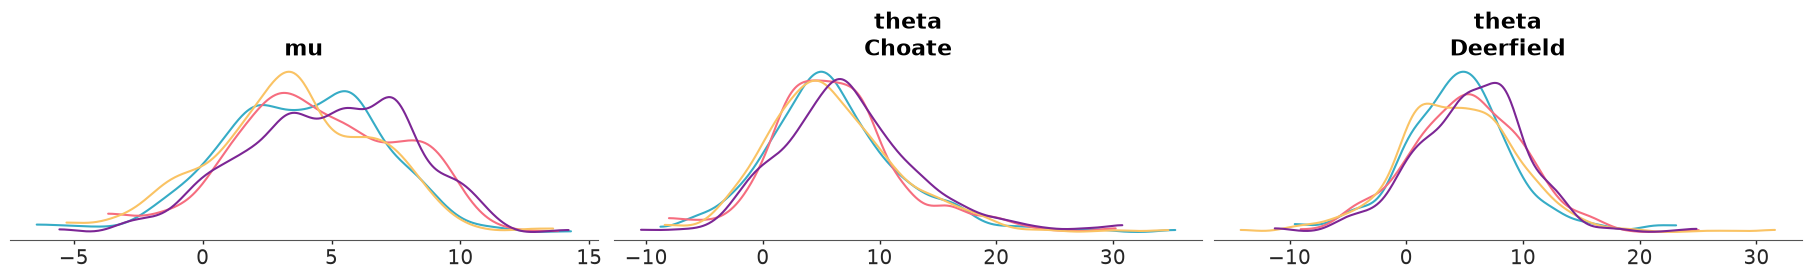

In [ ]:
pc = azp.plot_dist(
    idata,
    var_names=["mu", "theta"],  # select only two variables
    coords={"school": ["Choate", "Deerfield"]},  # select only two schools
    sample_dims=["draw"],  # reduce on the draw dimension, i.e., keep the chain dimension
    aes={"color": ["chain"]},  # map color aesthetic to chain dimension
    aes_by_visuals={"point_estimate": {"color": ["chain"]}},  # add color aesthetic to point_estimate visual by chain dimension
    cols=["__variable__", "school"],  # facet by variable and school, __variable__ is a special PlotCollection dimension
    visuals={
        "point_estimate_text": False,  # remove the text of the point estimates
        "point_estimate": False,  # remove the point estimates
        "credible_interval": False,  # remove the credible intervals
    },
)

## PlotCollection: Peeking Under the Hood

ArviZ plots are generated by first populating a `PlotCollection` object with the graphical elements that will be used to generate the final figure. PlotCollection provides the logic to loop over each plot, assign the correct data, aesthetics, and other properties to each plot, and then render them in a single figure. You can learn about it in the {ref}`intro to PlotCollection  <use_plotcollection>` tutorial.

When using batteries-included plots you don't usually need to directly interact with PlotCollection, you will only need it, if you want to create {ref}`your custom plot <compose_own_plot>`, or to perform some tweaks that can not be achieved via the provided arguments. For instance, to manually set the limit of the x-axis for the variable `mu` we can do:

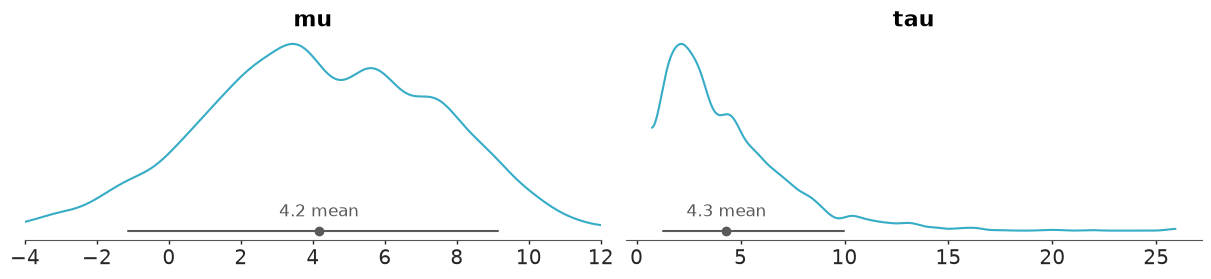

In [ ]:
pc = azp.plot_dist(idata, var_names=["mu", "tau"])

pc.get_viz("plot", "mu").set_xlim(-4, 12);

This works because a PlotCollection object stores information like the matplotlib axes, that we can access and modify directly.

In [ ]:
pc.get_viz("plot", "mu")

<Axes: title={'center': 'mu'}>

## Plotting backends

So far we have been using the matplotlib backend, but three other backends are available, `plotly`, `bokeh`, and `none`. The first two produce actual plots, while the last one does not produce any plot, for most common use you should not need to worry about the `none` backend. Which backend to use depends on your needs and preferences. To use a given backend it must be installed in your environment. You can have one, two, or all of them installed at the same time. You can globally set the backend by changing the value of:

```python
azb.rcParams["plot.backend"]
```

or by setting the `backend` argument in each plotting function.

One important thing to understand is that the "structure" of PlotCollection is the same for all backends, but the actual information stored will change. For example

In [ ]:
import plotly.io as pio

pio.renderers.default = "png"  # have plotly render as embedded png images

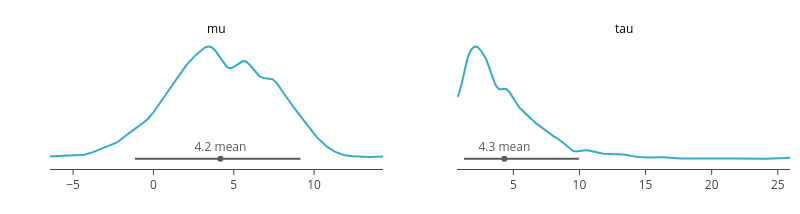

In [ ]:
pc = azp.plot_dist(
    idata,
    var_names=["mu", "tau"],
    backend="plotly"
)
pc.show()

In [ ]:
print(pc.get_viz("plot", "mu"))

See? We can still access `pc.get_viz("plot", "mu")`, as when the backend was matplotlib, but its content is not the same as before.

### Backend agnostic functionality
To support all these different backends, arviz-plots exposes a subset of their features through a common API. This section will cover the key elements you can take advantage of across backends when using arviz-plots. For more details on each specific backend see {ref}`api_backends`.

#### Default aesthetic cycle aliases
arviz-plots has default property cycles which are used when an aesthetic mapping is requested without providing values for it. We did that in the previous examples in fact. Using only `aes={"color": ["school"]}` as argument to `plot_dist` we ended up with the full school->color mapping.

Moreover, it is also possible to use `Cn` aliases to indicate you want that aesthetic to take the value of the n-th element in the default cycle. This is valid for `color`, `edgecolor`, `facecolor`, `linestyle` and `marker`.

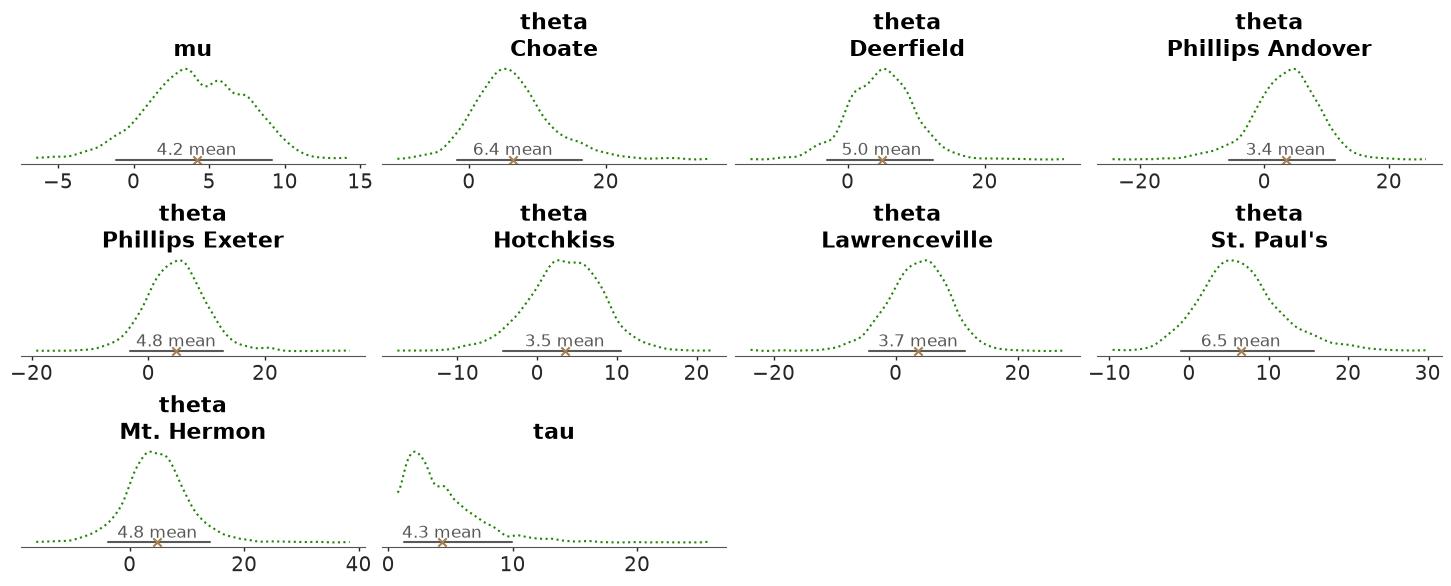

In [ ]:
azp.plot_dist(
    idata,
    visuals={
        "dist": {"linestyle": "C2", "color": "C4"},
        "point_estimate": {"marker": "C3", "color": "C7"}
    }
);

#### ArviZ themes
arviz-plots provides 6 custom themes, which are available for all 3 backends: `arviz-cetrino`, `arviz-tenui`, `arviz-variat`, `arviz-vibrant`, `arviz-tumma` and `arviz-darkgrid`. The functions inside the {ref}`style <api_style>` submodule of `arviz_plots` allow interfacing with these themes, by default applying them to all installed backends.

In [ ]:
azp.style.use("arviz-tumma")

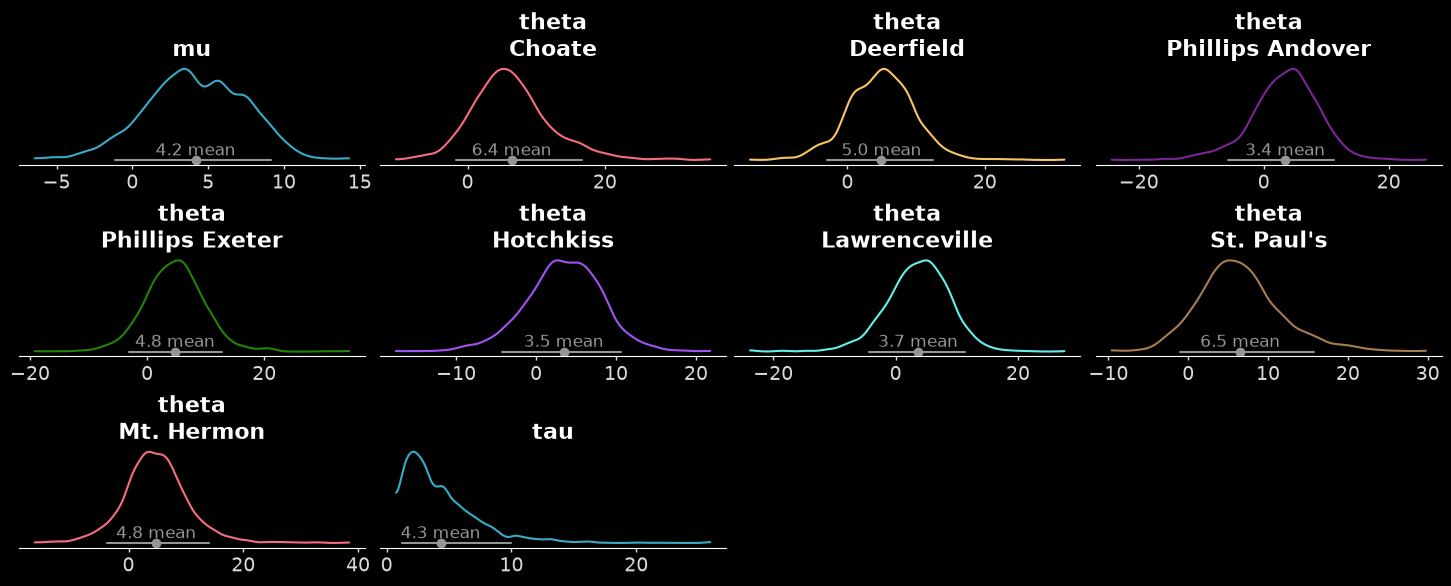

In [ ]:
azp.plot_dist(idata, aes={"color": ["school"]});

#### Background dependent colors

In addition to the cycle related aliases, there are also aliases available for colors dependent on the background color of the figure.
Their goal is to make supporting for both light and dark themes easier, but can also help make your own visualizations more accessible.

These aliases are `Bn` with the `n` index limited to the 0-3 range and are only valid for color related arguments: `color`, `edgecolor` and `facecolor`.
The meaning of each alias is the following:

  - `B0` -> the background color of the currently active theme
  - `B1` -> a color with high contrast with `B0` (21:1 contrast for black or white backgrounds)
  - `B2` -> a color with muted contrast with `B0` (7:1 contrast for black or white backgrounds). This color is more muted than `B1` but still high contrast enough for accessible text within image or thin visual elements.
  - `B3` -> a color with muted contrast with `B0` (3:1 contrast for black or white background). This color is even more muted than `B2` and might not be easily readable for everyone. It is still adequate for complementary graphical elements like grid lines or borders.

We can use these aliases to mute the plot titles and to give the appearance of empty circle to the marker, along with some more contrast:

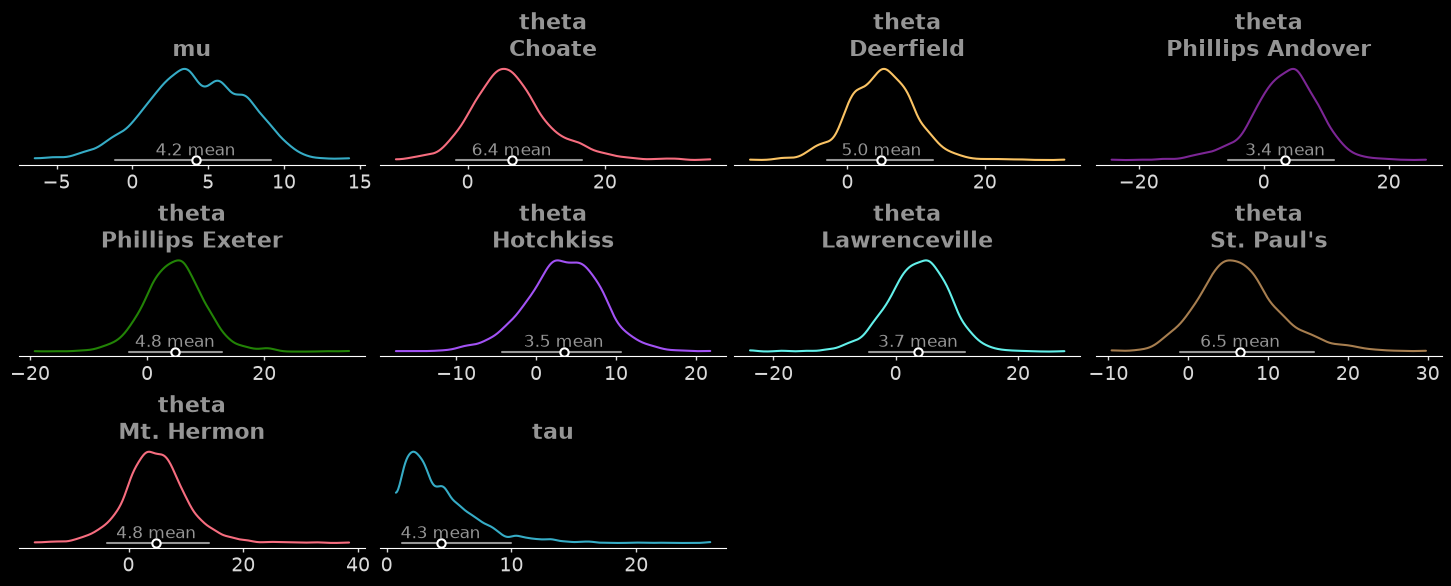

In [ ]:
azp.plot_dist(
    idata,
    aes={"color": ["school"]},
    visuals={
        "point_estimate": {"facecolor": "B0", "edgecolor": "B1", "width": 1.5},
        "title": {"color": "B2"},
    }
);

Now let's try these same arguments using a different theme and backend:

In [ ]:
azp.style.use("arviz-variat")

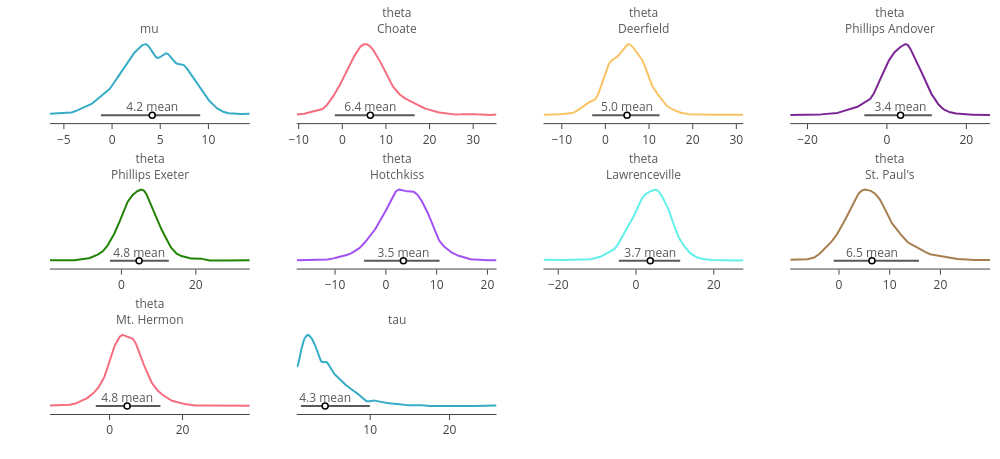

In [ ]:
pc = azp.plot_dist(
    idata,
    backend="plotly",
    aes={"color": ["school"]},
    visuals={
        "point_estimate": {"facecolor": "B0", "edgecolor": "B1", "width": 1.5},
        "title": {"color": "B2"},
    }
)
pc.show()

## Combining plots


Sometimes we want to combine different plots into a single figure. For example, we may want to plot the posterior distribution of the variable `mu` with a KDE and a ECDF in the same figure. We can do that using the `combine_plots` function. This function takes a `DataTree` (or other valid input) and a list of plotting functions.

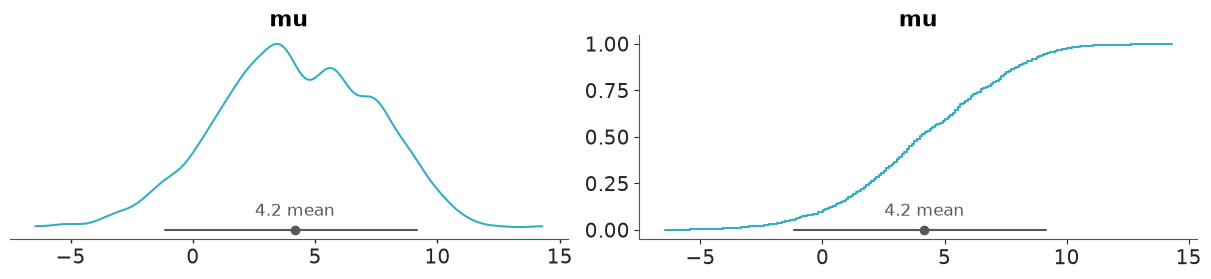

In [ ]:
pc = azp.combine_plots(
    idata,
    [
        (azp.plot_dist, {"kind": "kde"}),
        (azp.plot_dist, {"kind": "ecdf"}),
    ],
    var_names=["mu"],
)


The list of plots can be of different types, but some restrictions apply, like they should operate on the same group and variable names.

/home/osvaldo/proyectos/00_BM/arviz-devs/arviz-plots/src/arviz_plots/plots/loo_pit_plot.py:184: UserWarning: 'sample_dims' is currently not supported in plot_loo_pit and will be ignored
  warnings.warn(


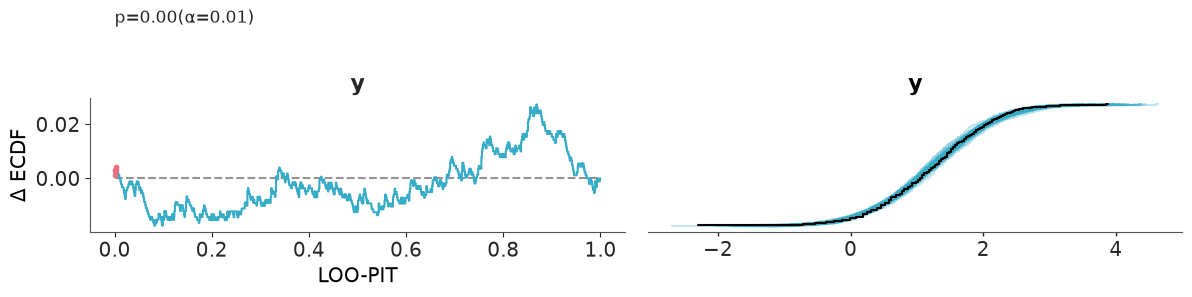

In [ ]:
data = azb.load_arviz_data("radon")
pc = azp.combine_plots(
    data,
    [
        (azp.plot_loo_pit, {}),
        (azp.plot_ppc_dist, {"kind": "ecdf"}),
    ],
    group="posterior_predictive",
)

:::{seealso}
* [arviz-base](https://arviz-base.readthedocs.io/en/latest/) data related functionality, including converters from different PPLs.
* [arviz-stats](https://arviz-stats.readthedocs.io/en/latest/) for statistical summaries, diagnostics, metrics and other estimators.
* [Exploratory Analysis of Bayesian Models](https://arviz-devs.github.io/EABM/) online book. 
* The {ref}`intro to PlotCollection  <use_plotcollection>` tutorial, for more advanced usage of ArviZ plotting functions.
* The {ref}`your custom plot <compose_own_plot>` tutorial, to learn how to create your own custom plots using ArviZ.
:::